In [1]:
!pip install numpy matplotlib pillow


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


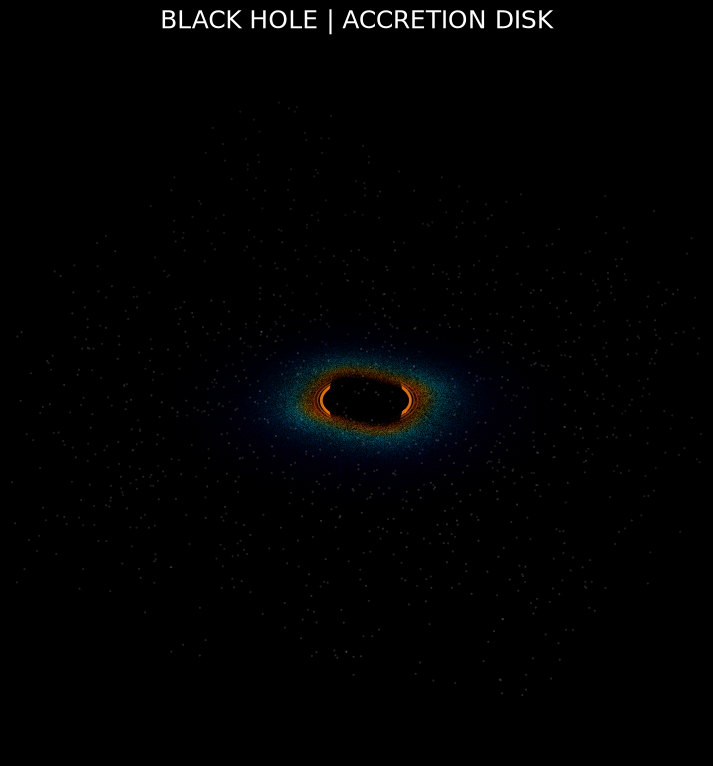

In [2]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.colors import LinearSegmentedColormap

# Ustawienia
np.random.seed(42)

fig = plt.figure(figsize=(12, 9), facecolor="black")
ax = fig.add_subplot(111, projection="3d")
ax.set_facecolor("black")

# Kolorystyka
colors = ["#050018", "#170052", "#0055aa",
          "#00d9ff", "#ffb000", "#ff3300"]

cmap = LinearSegmentedColormap.from_list(
    "cosmos", colors
)

# Dysk akrecyjny
n = 180000

theta = np.random.uniform(0, 2*np.pi, n)
r = np.random.uniform(2.0, 8.0, n)

# Spiralne zakrzywienie
spiral = theta + 2.5 * np.log(r)

x = r * np.cos(spiral)
y = r * np.sin(spiral)

# Delikatne odkształcenie przestrzeni
z = 0.15 * np.sin(3 * spiral) * np.exp(-r/8)
z += np.random.normal(0, 0.08, n)

# Intensywność światła
intensity = 1 / (r**0.7)
intensity = (intensity - intensity.min())
intensity /= intensity.max()

# Wizualizacja dysku
scatter = ax.scatter(
    x, y, z,
    c=intensity,
    cmap=cmap,
    s=0.12,
    alpha=0.65,
    linewidths=0
)

# Czarna dziura
u = np.linspace(0, 2*np.pi, 100)
v = np.linspace(0, np.pi, 100)

R = 1.5

xs = R * np.outer(np.cos(u), np.sin(v))
ys = R * np.outer(np.sin(u), np.sin(v))
zs = R * np.outer(np.ones_like(u), np.cos(v))

ax.plot_surface(
    xs, ys, zs,
    color="black",
    shade=True
)

# Jasny pierścień wokół czarnej dziury
t = np.linspace(0, 2*np.pi, 500)

for radius, width, alpha in [
    (1.8, 0.05, 0.9),
    (1.95, 0.025, 0.5),
    (2.1, 0.02, 0.3)
]:
    ax.plot(
        radius*np.cos(t),
        radius*np.sin(t),
        np.zeros_like(t),
        color="#ff7b00",
        linewidth=width*40,
        alpha=alpha
    )

# Gwiazdy w tle
stars = 1200

sx = np.random.uniform(-12, 12, stars)
sy = np.random.uniform(-12, 12, stars)
sz = np.random.uniform(-5, 5, stars)

ax.scatter(
    sx, sy, sz,
    color="white",
    s=0.15,
    alpha=0.5
)

# Ustawienia przestrzeni
ax.set_xlim(-9, 9)
ax.set_ylim(-9, 9)
ax.set_zlim(-5, 5)

ax.set_axis_off()

ax.set_title(
    "BLACK HOLE | ACCRETION DISK",
    color="white",
    fontsize=18,
    pad=25
)

# Animacja obrotu kamery
def animate(frame):
    ax.view_init(
        elev=25 + 8*np.sin(frame/100),
        azim=frame
    )
    return scatter,

animation = FuncAnimation(
    fig,
    animate,
    frames=360,
    interval=40,
    blit=False
)

plt.show()

# Aby zapisać animację jako GIF:
# animation.save("black_hole.gif", writer="pillow", fps=25)
